# 1.4 — Convolutional Neural Network on EuroSAT satellite images

*Based on Algirdas Laukaitis' CNN notebook (CIFAR-10), re-done with different data.*

**What changed compared with the original notebook**

| | Original | This notebook |
|---|---|---|
| Data | CIFAR-10: photos of everyday objects | **EuroSAT RGB: Sentinel-2 satellite images of land in Europe** |
| Image size | 32×32×3 | **64×64×3** |
| Classes | 10 (airplane, cat, truck…) | 10 land-use types (Forest, River, Highway…) |
| Splits | train / test (test also used for validation) | **train / validation / test**, test used only once at the end |
| Extra | — | class balance check, loss curves, confusion matrix, prediction examples, numeric check of the hand-made convolution |

The structure stays the same: **Part 1** trains a CNN, **Part 2** looks inside it (filters, feature maps, convolution by hand), **Part 3** compares it with a plain multilayer perceptron (MLP).

Run with **Runtime → Change runtime type → T4 GPU**.

<br>

---

# PART 1

### <font color='SeaGreen'>Download and prepare the EuroSAT dataset</font>

EuroSAT contains 27,000 RGB images (64×64 pixels) cut from Sentinel-2 satellite photos. Each image shows one type of land use:
AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake.

We load the version published on Hugging Face (`timm/eurosat-rgb`), which is already split into
16,200 training, 5,400 validation and 5,400 test images.

In [1]:
#@title Imports
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

tf.keras.utils.set_random_seed(42)   # same starting weights every run, so results are repeatable
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
#@title Load EuroSAT from Hugging Face and convert to NumPy arrays
!pip install -q datasets
from datasets import load_dataset

ds = load_dataset("timm/eurosat-rgb")
print(ds)

class_names = ds["train"].features["label"].names   # the 10 class names, in label order 0..9

def to_arrays(split):
    images = np.stack([np.array(img.convert("RGB")) for img in split["image"]])
    labels = np.array(split["label"]).reshape(-1, 1)
    return images, labels

train_images, train_labels = to_arrays(ds["train"])
val_images,   val_labels   = to_arrays(ds["validation"])
test_images,  test_labels  = to_arrays(ds["test"])

print("classes:", class_names)
print("train:", train_images.shape, train_labels.shape)
print("val:  ", val_images.shape, val_labels.shape)
print("test: ", test_images.shape, test_labels.shape)

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 55.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.4MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16200 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 16200
    })
    validation: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
    test: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
})
classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
train: (16200, 64, 64, 3) (16200, 1)
val:   (5400, 64, 64, 3) (5400, 1)
test:  (5400, 64, 64, 3) (5400, 1)


In [3]:
#@title Normalize pixel values from 0..255 to 0..1
# float32 halves the memory compared with the float64 that a plain "/ 255.0" would create
train_images = train_images.astype("float32") / 255.0
val_images   = val_images.astype("float32") / 255.0
test_images  = test_images.astype("float32") / 255.0

print(train_images.dtype, train_images.min(), train_images.max())

float32 0.0 1.0


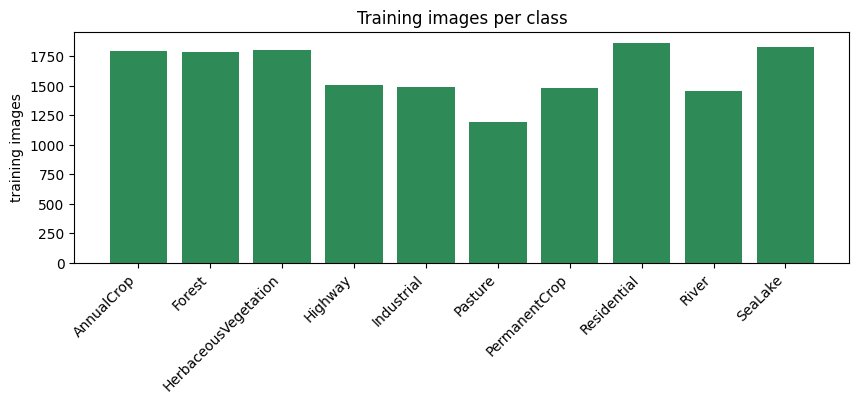

In [4]:
#@title Are the classes balanced?
counts = np.bincount(train_labels.ravel(), minlength=len(class_names))
plt.figure(figsize=(10, 3))
plt.bar(class_names, counts, color="seagreen")
plt.xticks(rotation=45, ha="right")
plt.ylabel("training images")
plt.title("Training images per class")
plt.show()

<br>

---
### <font color='SeaGreen'>Let's plot the first 100 images</font>

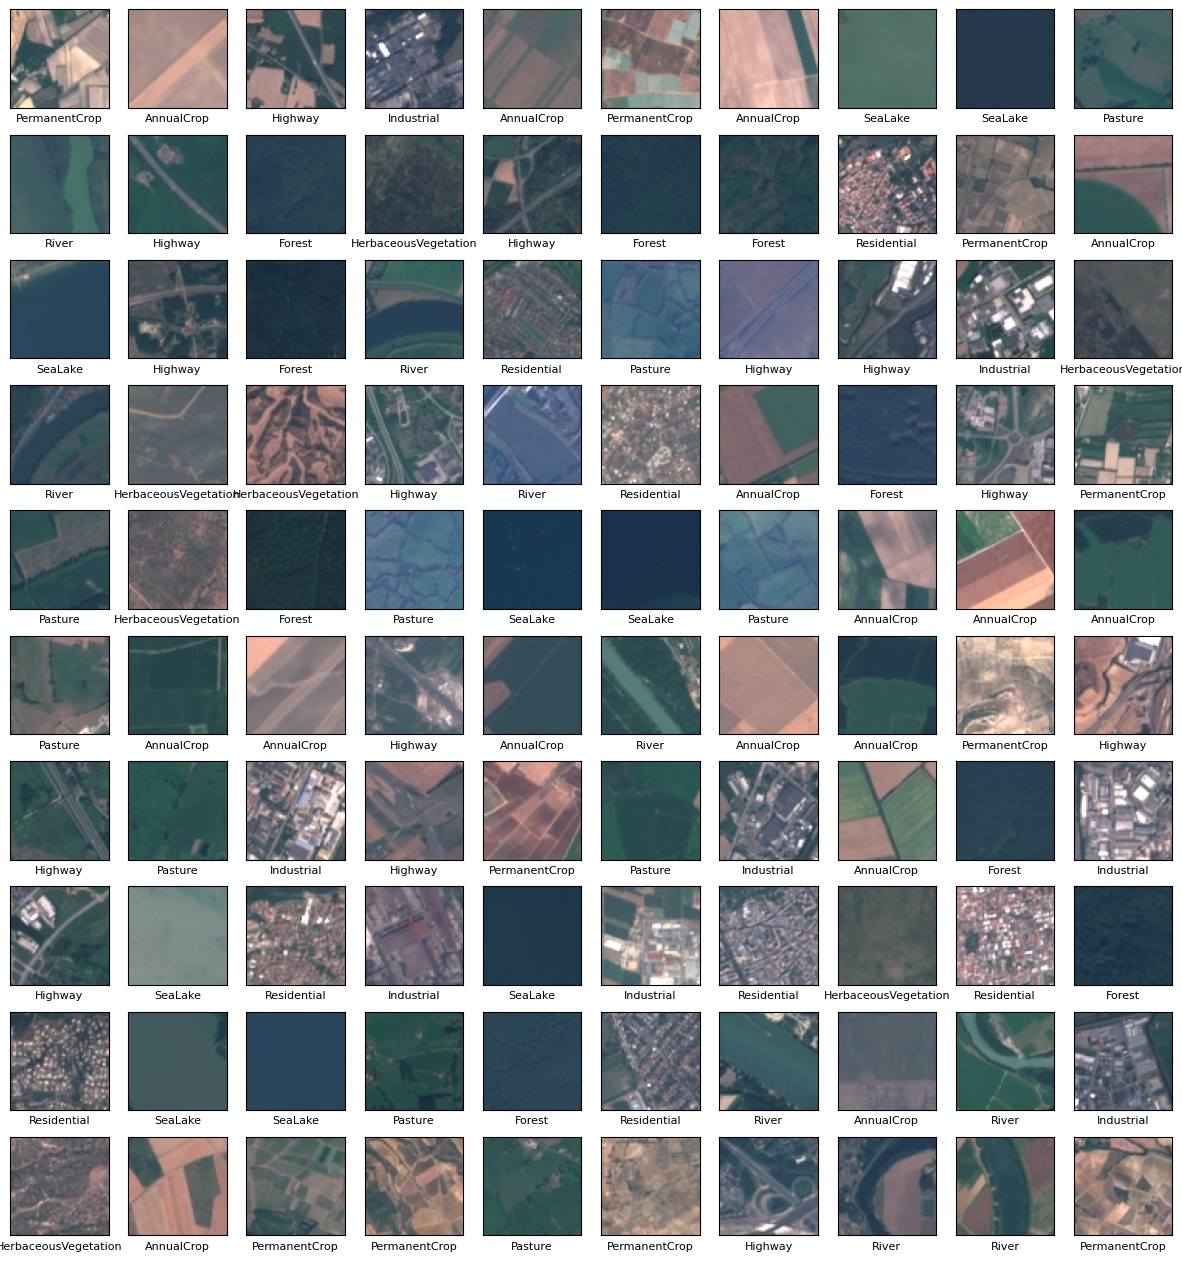

In [5]:
#@title Look at 100 training images to check that images and labels match
plt.figure(figsize=(15, 16))
for i in range(100):
    plt.subplot(10, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]], fontsize=8)
plt.show()

<br><br>

# <font color='SeaGreen'>Convolutional Neural Network</font>        <img src="https://upload.wikimedia.org/wikipedia/commons/6/63/Typical_cnn.png" width=500 height=150>

<br>

---
### <font color='SeaGreen'>Step 2. Model</font>

Same idea as the original: three `Conv2D` layers that detect patterns, `MaxPooling2D` layers that shrink the image, then `Dense` layers that decide the class.

Two changes for the new data:
* `layers.Input(shape=(64, 64, 3))` — the images are now 64×64 (the modern Keras way of giving the input size, so no warning).
* **One extra `MaxPooling2D` after the third convolution.** The images have 4× more pixels, so without it the `Flatten` layer would output 12×12×64 = 9,216 values and the first `Dense` layer alone would need ~590,000 weights. With it: 6×6×64 = 2,304 values and ~147,000 weights.

In [6]:
model = models.Sequential()
model.add(layers.Input(shape=(64, 64, 3)))

model.add(layers.Conv2D(32, (3, 3), activation='relu'))   # 64x64x3  -> 62x62x32
model.add(layers.MaxPooling2D((2, 2)))                    #          -> 31x31x32
model.add(layers.Conv2D(64, (3, 3), activation='relu'))   #          -> 29x29x64
model.add(layers.MaxPooling2D((2, 2)))                    #          -> 14x14x64
model.add(layers.Conv2D(64, (3, 3), activation='relu'))   #          -> 12x12x64
model.add(layers.MaxPooling2D((2, 2)))                    # NEW      -> 6x6x64

model.add(layers.Flatten())                               #          -> 2304
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(len(class_names)))                 # 10 scores (logits), one per class

In [7]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.summary()  # Conv2D weights = filters * (3*3*input_channels + 1 bias)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 204,490 (798.79 KB)

 Trainable params: 204,490 (798.79 KB)

 Non-trainable params: 0 (0.00 B)

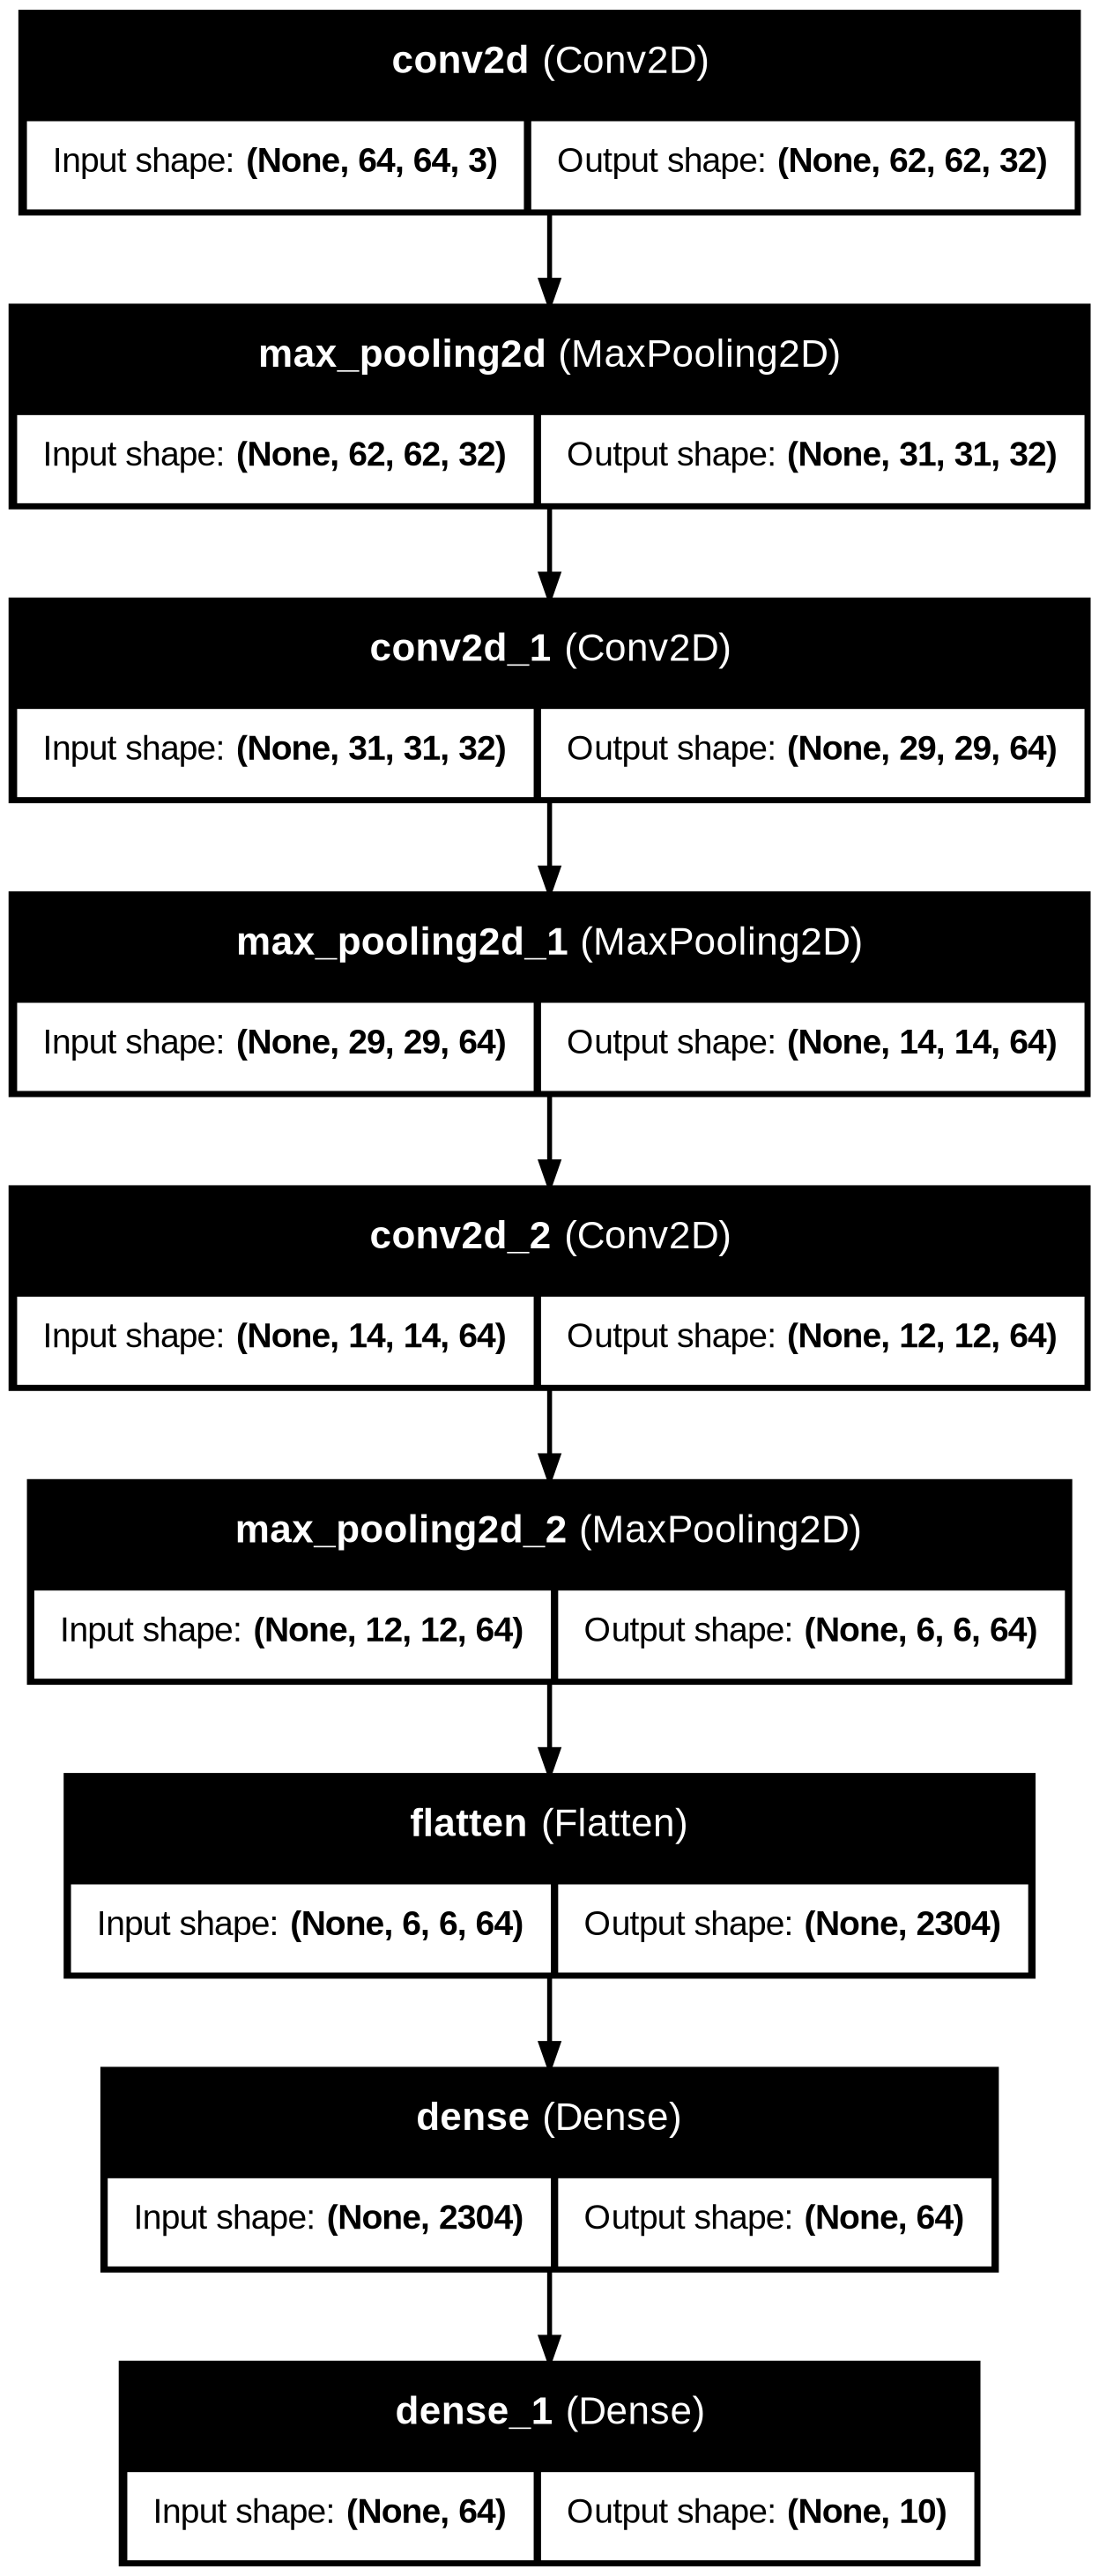

In [8]:
from tensorflow.keras.utils import plot_model
plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)

<br>

---
### <font color='SeaGreen'>Step 3. Train and evaluate the model</font>

Unlike the original, training is monitored on the separate **validation** split. The **test** split is used only once, after training.

In [9]:
history = model.fit(train_images, train_labels, epochs=15,
                    validation_data=(val_images, val_labels))

Epoch 1/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.4389 - loss: 1.3934 - val_accuracy: 0.4633 - val_loss: 1.4469
Epoch 2/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.6396 - loss: 0.9786 - val_accuracy: 0.6122 - val_loss: 1.0245
Epoch 3/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7225 - loss: 0.7643 - val_accuracy: 0.7111 - val_loss: 0.7732
Epoch 4/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7510 - loss: 0.6783 - val_accuracy: 0.7276 - val_loss: 0.7496
Epoch 5/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7754 - loss: 0.6132 - val_accuracy: 0.7513 - val_loss: 0.7157
Epoch 6/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7936 - loss: 0.5647 - val_accuracy: 0.7717 - val_loss: 0.6487
Epoch 7/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8062 - loss: 0.5335 - val_accuracy: 0.7609 - val_loss: 0.6946
Epoch 8/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8209 - loss: 0.4981 - val_accuracy: 

#### <font color='SeaGreen'>Evaluate the model</font>

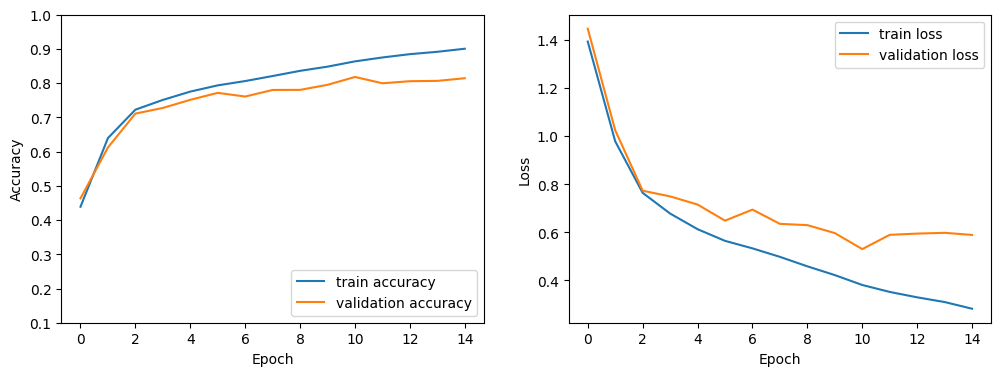

In [10]:
#@title Accuracy and loss per epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history['accuracy'], label='train accuracy')
ax1.plot(history.history['val_accuracy'], label='validation accuracy')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy'); ax1.set_ylim([0.1, 1])
ax1.legend(loc='lower right')

ax2.plot(history.history['loss'], label='train loss')
ax2.plot(history.history['val_loss'], label='validation loss')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.legend(loc='upper right')
plt.show()

# If validation loss starts rising while training loss keeps falling, the model is overfitting.

In [11]:
#@title Final score on the test images (never seen during training)
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
cnn_test_acc = test_acc
print(f"CNN test accuracy: {test_acc:.4f}")

169/169 - 1s - 3ms/step - accuracy: 0.8309 - loss: 0.5262
CNN test accuracy: 0.8309


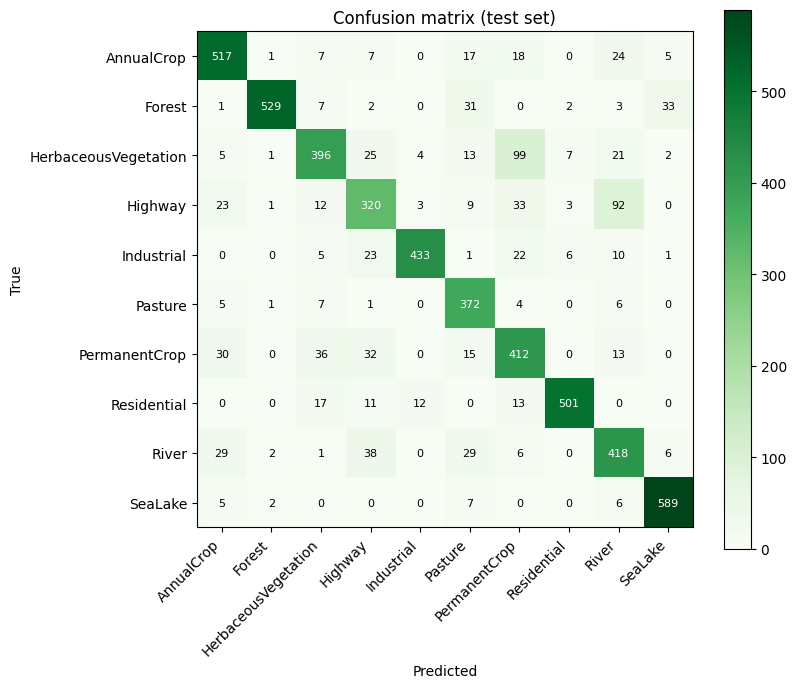

In [12]:
#@title Which classes get confused? (confusion matrix)
pred_labels = np.argmax(model.predict(test_images, verbose=0), axis=1)
cm = tf.math.confusion_matrix(test_labels.ravel(), pred_labels, num_classes=len(class_names)).numpy()

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap='Greens')
plt.xticks(range(len(class_names)), class_names, rotation=45, ha='right')
plt.yticks(range(len(class_names)), class_names)
plt.xlabel('Predicted'); plt.ylabel('True')
for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.title('Confusion matrix (test set)')
plt.colorbar()
plt.show()

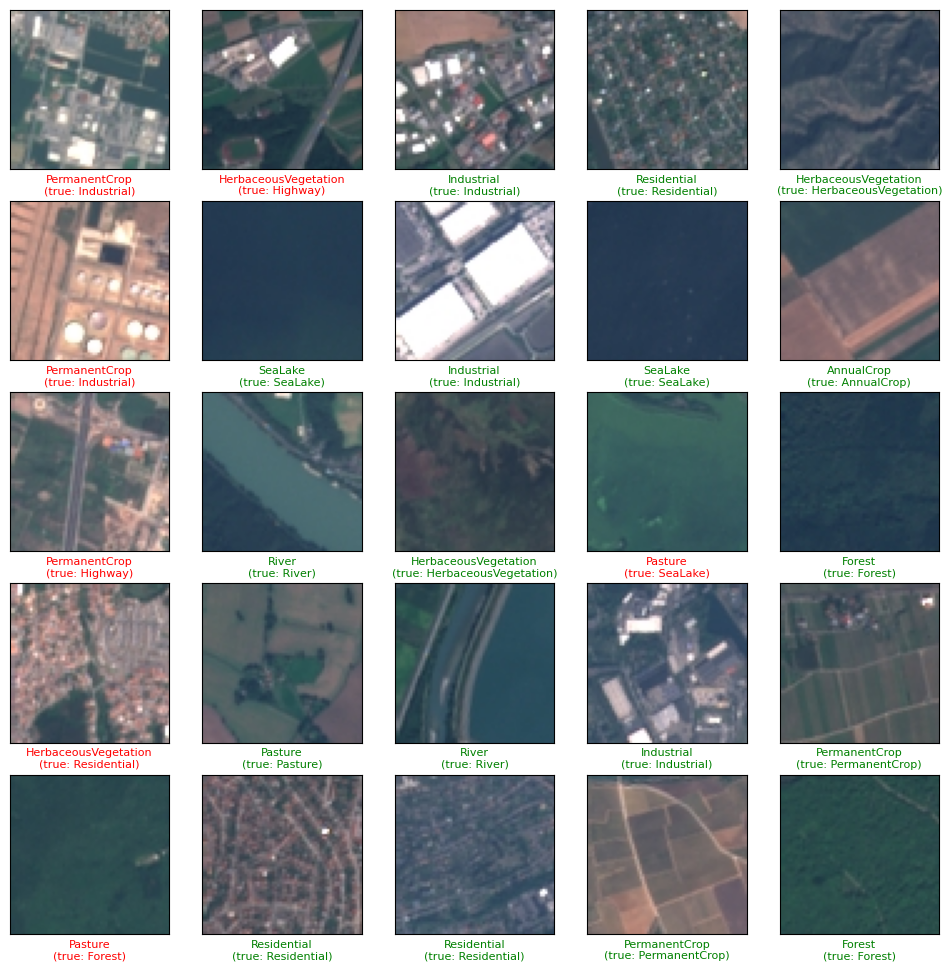

In [13]:
#@title 25 test images: green = correct, red = wrong
plt.figure(figsize=(12, 12))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([]); plt.yticks([])
    plt.imshow(test_images[i])
    true_name, pred_name = class_names[test_labels[i][0]], class_names[pred_labels[i]]
    plt.xlabel(f"{pred_name}\n(true: {true_name})", fontsize=8,
               color='green' if true_name == pred_name else 'red')
plt.show()

<br><br>

---
# PART 2

### <font color='SeaGreen'>Visualizing Filters and Feature Maps</font> <img src="https://upload.wikimedia.org/wikipedia/commons/1/19/2D_Convolution_Animation.gif" width=200 height=200>

The first convolutional layer has 32 filters. Each filter is a 3×3 grid of weights **for every colour channel** (3×3×3 = 27 numbers) plus one bias.
Below we plot them, feed one satellite image through the first layer, and then recompute one feature map by hand with NumPy to show that a convolution is just *multiply, sum, add bias, ReLU*.

filters: (3, 3, 3, 32)  biases: (32,)


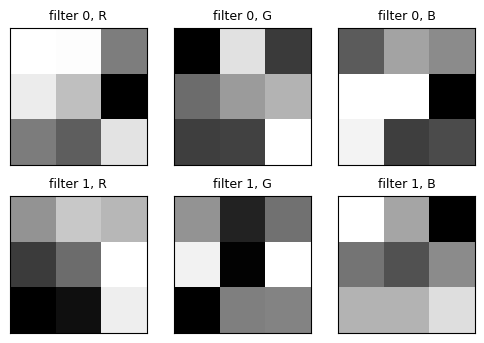

In [14]:
#@title First-layer filters: 2 filters x 3 colour channels
filters, biases = model.layers[0].get_weights()
print("filters:", filters.shape, " biases:", biases.shape)   # (3, 3, 3, 32) and (32,)

plt.figure(figsize=(6, 4))
ix = 1
for filter_i in range(2):
    filter_tmp = filters[:, :, :, filter_i]
    for channel_j, channel_name in enumerate(['R', 'G', 'B']):   # plot each channel separately
        ax = plt.subplot(2, 3, ix)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"filter {filter_i}, {channel_name}", fontsize=9)
        plt.imshow(filter_tmp[:, :, channel_j], cmap='gray')
        ix += 1
plt.show()

In [15]:
filter_tmp[:, :, 0]   # the 9 numbers of filter 1, red channel

array([[ 0.07072269,  0.12105917,  0.10444381],
       [-0.01344722,  0.03290541,  0.17359897],
       [-0.07065368, -0.0554736 ,  0.15678127]], dtype=float32)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step
feature maps: (1, 62, 62, 32)


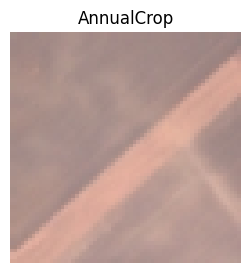

In [16]:
#@title Feature maps: output of the first layer for one image
model_layers_0 = tf.keras.Model(inputs=model.inputs, outputs=model.layers[0].output)  # model that stops after the first layer

IMG_INDEX = 1
img = np.expand_dims(train_images[IMG_INDEX], axis=0)   # add a batch dimension: (1, 64, 64, 3)
feature_maps = model_layers_0.predict(img)
print("feature maps:", feature_maps.shape)              # (1, 62, 62, 32)

plt.figure(figsize=(3, 3))
plt.imshow(train_images[IMG_INDEX]); plt.axis('off')
plt.title(class_names[train_labels[IMG_INDEX][0]])
plt.show()

In [17]:
#@title What the network actually sees: red channel numbers (top-left 8x8 corner of the 64x64 image)
red_channel = train_images[IMG_INDEX][:, :, 0]
for row in red_channel[:8, :8]:
    print(" ".join(f"{v:0.2f}" for v in row))

0.63 0.63 0.63 0.63 0.62 0.62 0.61 0.62
0.63 0.64 0.63 0.62 0.62 0.62 0.62 0.62
0.62 0.63 0.62 0.63 0.63 0.62 0.63 0.64
0.62 0.62 0.62 0.63 0.63 0.63 0.64 0.63
0.62 0.62 0.62 0.63 0.64 0.64 0.63 0.63
0.62 0.62 0.62 0.63 0.64 0.63 0.64 0.64
0.63 0.63 0.64 0.64 0.64 0.65 0.64 0.64
0.64 0.64 0.64 0.64 0.64 0.64 0.64 0.65


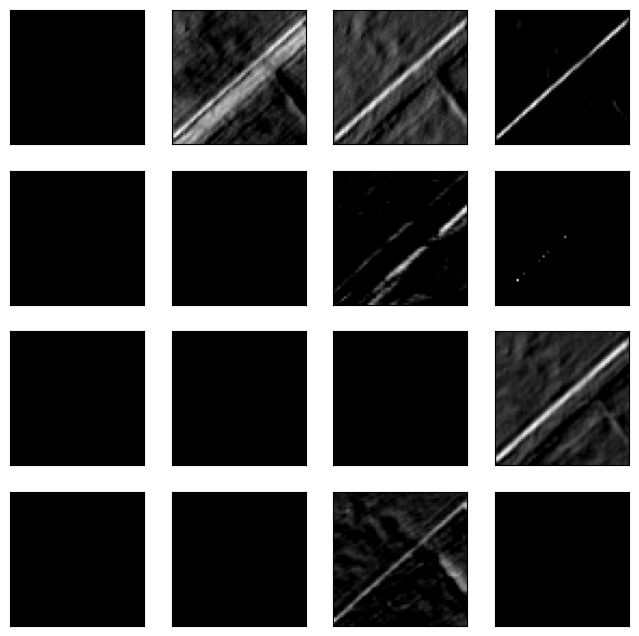

In [18]:
#@title 16 of the 32 feature maps. Each filter reacts to a different pattern.
plt.figure(figsize=(8, 8))
for ix in range(16):
    ax = plt.subplot(4, 4, ix + 1)
    ax.set_xticks([]); ax.set_yticks([])
    plt.imshow(feature_maps[0, :, :, ix], cmap='gray')
plt.show()

filter: (3, 3, 3)  bias: 0.017917827


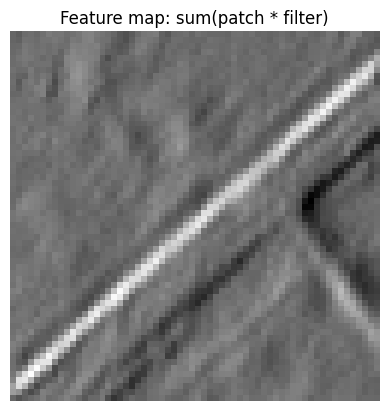

In [19]:
#@title Convolution by hand with filter k (no bias, no ReLU yet)
k = 2
filter = filters[:, :, :, k]          # (3, 3, 3)
bias = biases[k]
input_image = train_images[IMG_INDEX] # (64, 64, 3)
print("filter:", filter.shape, " bias:", bias)

out_h = input_image.shape[0] - filter.shape[0] + 1   # 64 - 3 + 1 = 62
out_w = input_image.shape[1] - filter.shape[1] + 1
feature_map = np.zeros((out_h, out_w))

for i in range(out_h):
    for j in range(out_w):
        patch = input_image[i:i+3, j:j+3, :]          # 3x3x3 piece of the image
        feature_map[i, j] = np.sum(patch * filter)    # multiply element by element, then add up all 27 numbers

plt.imshow(feature_map, cmap='gray'); plt.title("Feature map: sum(patch * filter)"); plt.axis('off')
plt.show()

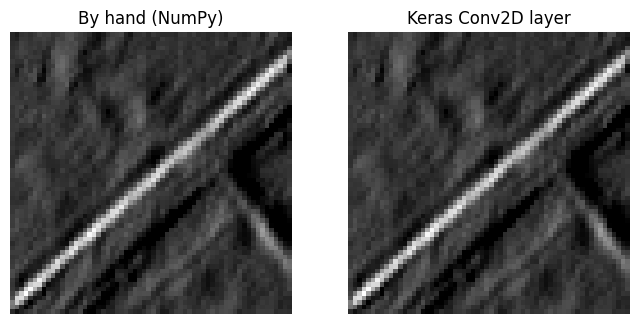

shapes: (62, 62) (62, 62)
largest difference: 8.568167686462402e-08
same result: True


In [20]:
#@title Add the bias and apply ReLU, then compare with what Keras computed
feature_map_manual = feature_map + bias
feature_map_manual[feature_map_manual < 0] = 0       # ReLU: negatives become 0

feature_map_keras = feature_maps[0, :, :, k]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(8, 4))
a1.imshow(feature_map_manual, cmap='gray'); a1.set_title("By hand (NumPy)"); a1.axis('off')
a2.imshow(feature_map_keras, cmap='gray');  a2.set_title("Keras Conv2D layer"); a2.axis('off')
plt.show()

print("shapes:", feature_map_manual.shape, feature_map_keras.shape)
print("largest difference:", np.max(np.abs(feature_map_manual - feature_map_keras)))
print("same result:", np.allclose(feature_map_manual, feature_map_keras, atol=1e-4))

<br><br><br>

---
# <font color='SeaGreen'>PART 3. Image classification with Multilayer perceptron</font> <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/46/Colored_neural_network.svg/250px-Colored_neural_network.svg.png" width=150 height=150>

Same data, but no convolutions: each image is flattened into one long list of 64×64×3 = 12,288 numbers, so the information about which pixels are neighbours is lost.

<br>

---
### <font color='SeaGreen'>Step 2. Model. Multilayer perceptron</font>

In [21]:
mlp = models.Sequential()
mlp.add(layers.Input(shape=(64, 64, 3)))
mlp.add(layers.Flatten())                        # -> 12288
mlp.add(layers.Dense(32, activation='relu'))
mlp.add(layers.Dense(64, activation='relu'))
mlp.add(layers.Dense(64, activation='relu'))
mlp.add(layers.Dense(len(class_names)))

mlp.compile(optimizer='adam',
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            metrics=['accuracy'])

In [22]:
#@title Let's display the architecture of the model
mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       393,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 400,170 (1.53 MB)

 Trainable params: 400,170 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

<br>

---
### <font color='SeaGreen'>Step 3. Train and evaluate the model</font>

In [23]:
mlp_history = mlp.fit(train_images, train_labels, epochs=15,
                      validation_data=(val_images, val_labels))

Epoch 1/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.2841 - loss: 1.8366 - val_accuracy: 0.2256 - val_loss: 1.9358
Epoch 2/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3511 - loss: 1.6940 - val_accuracy: 0.2654 - val_loss: 1.9292
Epoch 3/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3793 - loss: 1.6397 - val_accuracy: 0.3183 - val_loss: 1.7904
Epoch 4/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4010 - loss: 1.5954 - val_accuracy: 0.3987 - val_loss: 1.5905
Epoch 5/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4109 - loss: 1.5688 - val_accuracy: 0.4156 - val_loss: 1.5579
Epoch 6/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4230 - loss: 1.5451 - val_accuracy: 0.4291 - val_loss: 1.5383
Epoch 7/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4283 - loss: 1.5251 - val_accuracy: 0.4348 - val_loss: 1.5221
Epoch 8/15
507/507 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4338 - loss: 1.5118 - val_accuracy: 0.

#### <font color='SeaGreen'>Evaluate the model</font>

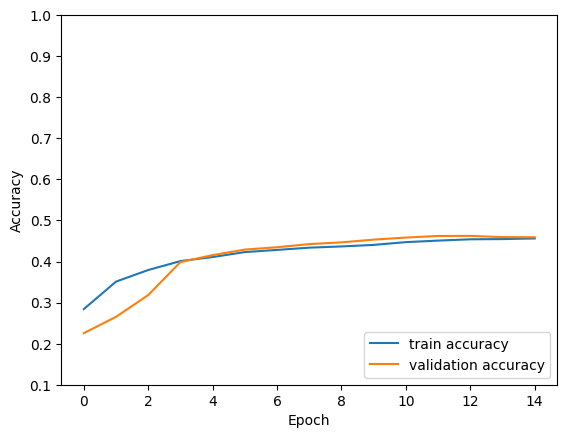

169/169 - 0s - 3ms/step - accuracy: 0.4702 - loss: 1.4415
MLP test accuracy: 0.4702


In [24]:
plt.plot(mlp_history.history['accuracy'], label='train accuracy')
plt.plot(mlp_history.history['val_accuracy'], label='validation accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.ylim([0.1, 1])
plt.legend(loc='lower right')
plt.show()

mlp_test_loss, mlp_test_acc = mlp.evaluate(test_images, test_labels, verbose=2)
print(f"MLP test accuracy: {mlp_test_acc:.4f}")

<br>

---
# <font color='SeaGreen'>CNN vs MLP</font>

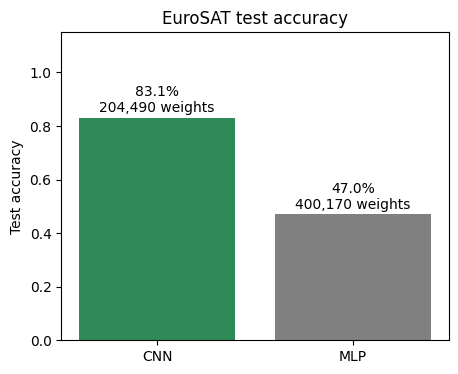

In [25]:
#@title Side-by-side comparison
names = ['CNN', 'MLP']
accs = [cnn_test_acc, mlp_test_acc]
params = [model.count_params(), mlp.count_params()]

plt.figure(figsize=(5, 4))
bars = plt.bar(names, accs, color=['seagreen', 'grey'])
for b, a, p in zip(bars, accs, params):
    plt.text(b.get_x() + b.get_width() / 2, a + 0.02, f"{a:.1%}\n{p:,} weights", ha='center')
plt.ylim([0, 1.15]); plt.ylabel('Test accuracy')
plt.title('EuroSAT test accuracy')
plt.show()

### <font color='SeaGreen'>Conclusions</font>

* **The CNN reached 83.1% test accuracy and the MLP only 47.0%**, on the same EuroSAT satellite images. Both beat random guessing (10%), but the CNN is far better.
* **The CNN won with about half as many weights**: 204,490 against the MLP's 400,170. So the difference comes from the network's structure, not its size.
* **Why:** the MLP flattens each 64×64×3 image into one row of 12,288 numbers, which loses which pixels sit next to each other. The CNN slides the same small filters over the whole image, so it recognises textures like water, forest or field rows wherever they appear. Satellite images are mostly textures and colours, which is exactly what convolution filters pick up.
* **Part 2 showed a convolution layer is simple arithmetic**: computing one feature map by hand in NumPy (multiply, sum, add bias, ReLU) gave the same result as the Keras layer.
* **Compared with the original CIFAR-10 notebook** (CNN 69.8%, MLP 43.2%), the same pattern holds on completely different data: CNNs are the better choice for images.